# Name That LLM – Explorative Datenanalyse

Aufgabe: Für einen Text vorhersagen, welches von 18 LLMs ihn geschrieben hat.

**Metrik: Balanced Accuracy**, also das Mittel der Recalls je Modell. Jedes Modell zählt gleich viel, auch wenn es im Test seltener vorkommt.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_train, load_test, load_sample_submission
from src.features import stylometric_features

pd.set_option("display.max_colwidth", 300)
sns.set_theme(style="whitegrid")

train, test, sample_sub = load_train(), load_test(), load_sample_submission()
print(train.shape, test.shape, sample_sub.shape)
train.head()

(2699, 5) (3, 2) (3, 2)


,id,prompt_id,text,model,family
0,0018b3765972,p081,"When a language dies, a particular astronomy dims: not only names for stars, but whole grammars of attention that taught speakers how to read the night. Some tongues map the sky by kinship, binding the Milky Way to ancestors, rivers, or the migration paths of birds; others encode lunar phases as...",qwen3.8-max,qwen
1,0041ac86ee93,p073,"Data science communities matter because they accelerate learning through shared knowledge, code, and real-world problem-solving that no individual could develop alone. They connect beginners with experts, fostering mentorship across diverse industries and backgrounds. These networks drive innova...",claude-sonnet-5,claude
2,005a19083eae,p120,"In the final twilight of time, the last embers of ancient suns falter into silent rust, leaving behind a boundless sea of absolute frost. Galaxies have unspooled into phantom dust, their brilliant fires forgotten beneath the vast, indifferent hush of eternal equilibrium. No starlight pierces the...",gemini-3.6-flash,gemini
3,009319596f10,p073,"Data science communities matter because they turn a fast-moving, technically demanding field into a shared practice rather than a solitary race to keep up. Through meetups, forums, open-source projects, study groups, conferences, and informal peer networks, practitioners exchange methods, critiq...",gpt-5.6-terra,gpt
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone cradle a whisper of fluid, and every time you turn your head, that liquid sways like a tide. Nothing announces it—no sound, no shimmer—yet these microscopic canals read every tilt and spin, telling your eyes how to hold the horizon steady. Step off ...",glm-5.3-flash,glm


## 1. Struktur der Daten
- 18 Modelle aus 6 Familien, je ca. 150 Texte (balanciert)
- 150 Prompts, **jeder Prompt wurde von (fast) allen 18 Modellen beantwortet**
- Der Test hat nur 3 Zeilen; der echte Testdatensatz ist vermutlich versteckt.

{'id': 0, 'prompt_id': 0, 'text': 0, 'model': 0, 'family': 0}
Prompts: 150
Modelle je Prompt: {18: 149, 17: 1}


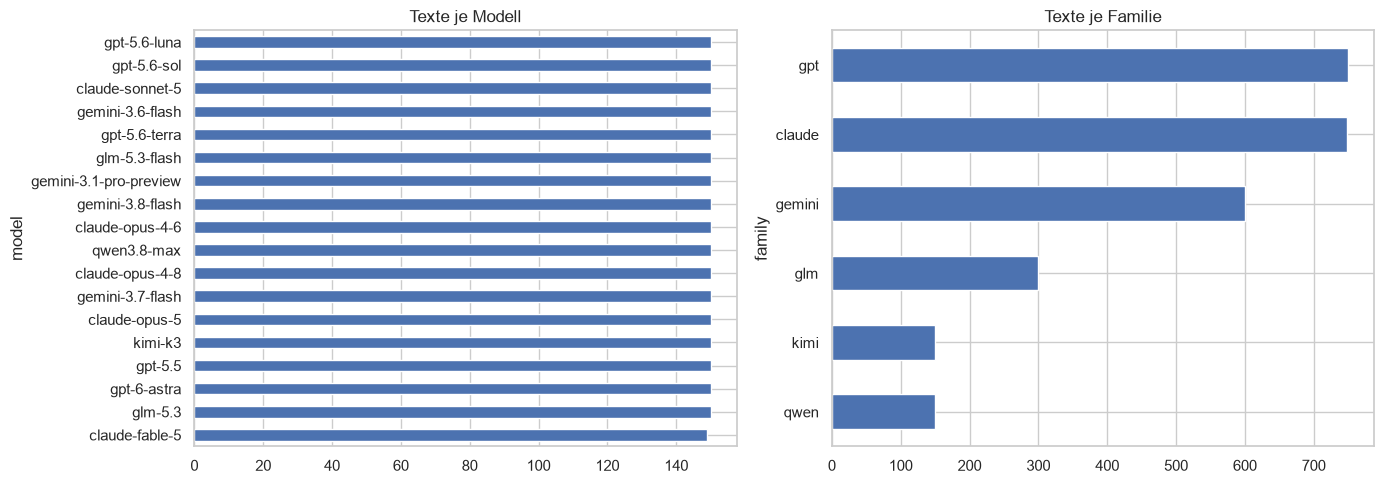

In [2]:
print(train.isna().sum().to_dict())
print("Prompts:", train.prompt_id.nunique())
print("Modelle je Prompt:", train.groupby("prompt_id").model.nunique().value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
train.model.value_counts().sort_values().plot.barh(ax=axes[0], title="Texte je Modell")
train.family.value_counts().sort_values().plot.barh(ax=axes[1], title="Texte je Familie")
plt.tight_layout()

## 2. Gleicher Prompt, verschiedene Modelle
Hier sieht man direkt, wie sich die Stile unterscheiden.

In [3]:
pid = train.prompt_id.iloc[0]
train.loc[train.prompt_id == pid, ["model", "text"]].sort_values("model")

,model,text
1541,claude-fable-5,"When a language dies, a way of seeing the sky dies with it: names for constellations no atlas records, verbs that made stars kin rather than objects, seasons read in moonlight's grammar. The cosmos loses nothing, yet we lose a mirror—one irreplaceable angle from which the universe once contempla..."
739,claude-opus-4-6,"When a language dies, it carries into silence not merely vocabulary but entire architectures of thought—constellations named for forgotten myths, verb tenses that encoded the speaker's relationship to starlight, grammatical structures that made no distinction between the observer and the observe..."
669,claude-opus-4-8,"When a language falls silent for the last time, an entire observatory of the mind collapses with it, and the cosmos loses one of the ways it was known. Every tongue encodes a particular geometry of attention: a people who named the seven sisters of the Pleiades might have counted six, or nine, o..."
307,claude-opus-5,"When the last speaker of a language falls silent, a constellation goes unnamed forever. Somewhere a people once heard the river as a verb, counted seasons by the migration of one particular bird, and held a word for the grief that arrives only at dusk. These were not translations waiting to happ..."
2091,claude-sonnet-5,"When a language dies, an entire architecture of the sky collapses—star paths that guided fishermen vanish, constellations shaped like ancestral animals unseen by other eyes dissolve into anonymous points, and words for the particular blue of dusk before monsoon rains fall silent forever. Gone to..."
256,gemini-3.1-pro-preview,"When a language dies, we do not merely lose a catalog of exotic syntax or a repository of ancestral idioms; we lose an entirely unique architecture of the cosmos. Every spoken tongue acts as a bespoke lens through which the universe is refracted, organizing the chaos of the night sky into conste..."
2631,gemini-3.6-flash,"When a language dies, an entire universe quietly collapses, erasing untranslatable maps of the night sky, untamed relationships with the soil, and delicate verb tenses that capture the fluid nature of time. Without those ancient vocalizations, humanity permanently forgets how to name the precise..."
75,gemini-3.7-flash,"When a language dies, an entire universe folds inward, erasing unmapped constellations of thought. Unique grammars of starlight, ancestral understandings of time's circular breath, and intimate dialogues with the wilderness vanish forever, reducing the cosmos to a flatter, emptier silence."
382,gemini-3.8-flash,"When an ancient tongue dies, a singular window into the cosmos permanently shutters. Extinction erases not merely vocabulary, but an entire cosmology’s delicate grammar: celestial architectures that charted time outside modern linearity, unmapped constellations woven from ancestral memory, and s..."
1470,glm-5.3,"When a language dies, a universe dims with it: the Navajo word holding a star as both ancestor and promise, the Aboriginal songlines tracing an emu in the Milky Way's dark river, the grammar that told time by the sun's path, not clocks. Each tongue carried its own cosmos—directions felt in the b..."


## 3. Stilometrische Features

In [4]:
stylo = stylometric_features(train.text)
stylo["model"], stylo["family"] = train.model, train.family
stylo.groupby("model").mean(numeric_only=True).round(2)

,n_chars,n_words,n_sents,n_paras,words_per_sent,sent_len_std,avg_word_len,type_token_ratio,upper_ratio,non_ascii_ratio,...,per100w_curly_dquote,per100w_straight_apos,per100w_straight_dquote,per100w_colon,per100w_semicolon,per100w_comma,per100w_paren,per100w_question,per100w_exclam,per100w_ellipsis
model,,,,,,,,,,,,,,,,,,,,,
claude-fable-5,731.02,115.74,4.71,1.0,24.89,6.14,5.24,0.81,0.01,0.0,...,0.00,0.99,0.14,0.66,0.34,9.04,0.03,0.04,0.00,0.0
claude-opus-4-6,771.21,117.40,4.27,1.0,27.85,7.29,5.52,0.81,0.01,0.0,...,0.00,0.96,0.17,0.37,0.12,7.65,0.00,0.03,0.00,0.0
claude-opus-4-8,809.81,126.32,5.07,1.0,24.44,6.88,5.34,0.80,0.01,0.0,...,0.00,0.88,0.13,0.49,0.19,9.40,0.01,0.04,0.00,0.0
claude-opus-5,762.81,125.87,5.16,1.0,24.38,8.65,4.96,0.78,0.01,0.0,...,0.00,0.98,0.20,0.79,0.58,8.25,0.01,0.05,0.02,0.0
claude-sonnet-5,816.58,123.95,4.55,1.0,27.14,6.12,5.50,0.82,0.01,0.0,...,0.00,1.45,0.23,0.58,0.23,9.46,0.00,0.01,0.01,0.0
gemini-3.1-pro-preview,782.97,119.71,5.77,1.0,20.32,5.23,5.48,0.80,0.01,0.0,...,0.00,0.12,0.03,0.16,0.16,7.55,0.00,0.05,0.01,0.0
gemini-3.6-flash,758.56,111.85,4.59,1.0,24.83,5.02,5.68,0.83,0.01,0.0,...,0.00,0.25,0.06,0.17,0.20,8.32,0.01,0.04,0.00,0.0
gemini-3.7-flash,828.69,118.04,4.81,1.0,24.06,5.03,5.89,0.84,0.01,0.0,...,0.00,0.17,0.00,0.17,0.20,8.20,0.01,0.03,0.00,0.0
gemini-3.8-flash,706.20,101.33,4.42,1.0,22.88,5.16,5.86,0.86,0.01,0.0,...,0.03,0.15,0.01,0.18,0.28,8.47,0.00,0.03,0.00,0.0


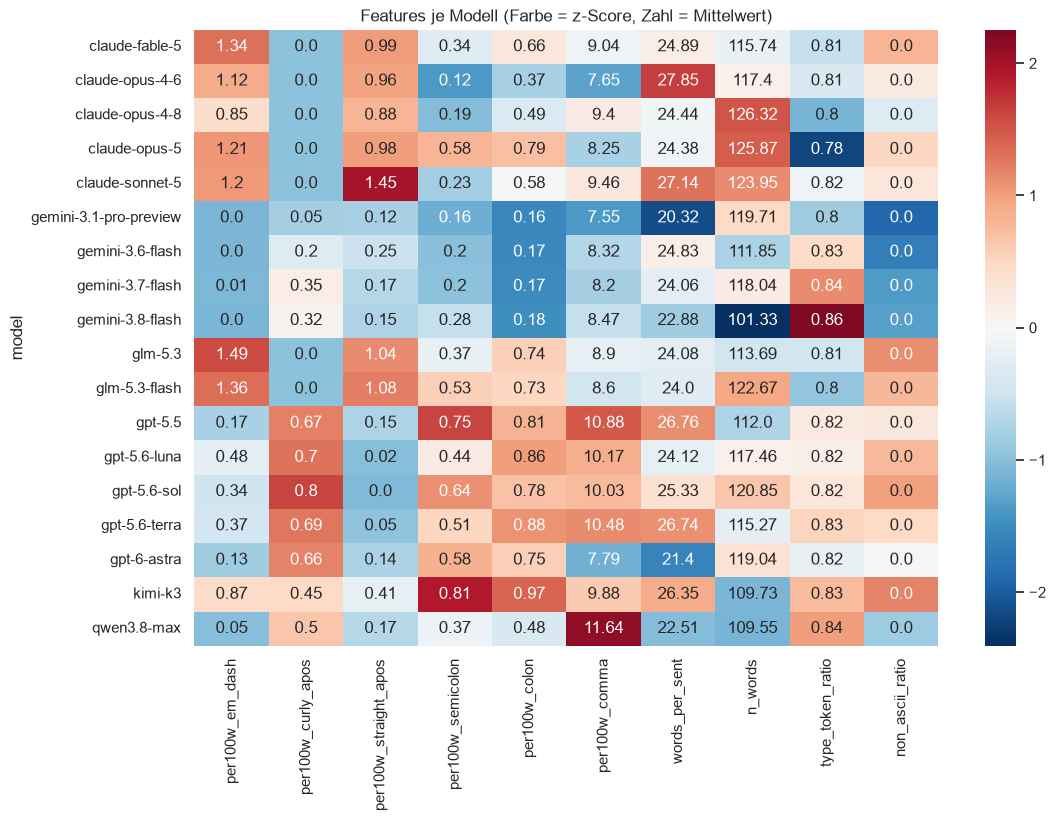

In [5]:
cols = ["per100w_em_dash", "per100w_curly_apos", "per100w_straight_apos", "per100w_semicolon",
        "per100w_colon", "per100w_comma", "words_per_sent", "n_words", "type_token_ratio", "non_ascii_ratio"]
m = stylo.groupby("model")[cols].mean()
m = m.loc[sorted(m.index)]
plt.figure(figsize=(12, 8))
sns.heatmap((m - m.mean()) / m.std(), cmap="RdBu_r", center=0, annot=m.round(2), fmt="")
plt.title("Features je Modell (Farbe = z-Score, Zahl = Mittelwert)");

**Beobachtungen:**
- **Gedankenstrich „—“**: Claude, GLM und Kimi nutzen ihn viel, Gemini praktisch nie.
- **Typografische Apostrophe „’“**: GPT, Gemini, Qwen und Kimi ja, Claude und GLM nie (sie nutzen gerade `'`).
- Länge und Satzlänge unterscheiden sich kaum und sind kein Hauptsignal.
- Folge: `lowercase=False` und Char-n-Gramme inklusive Interpunktion sind wichtig.

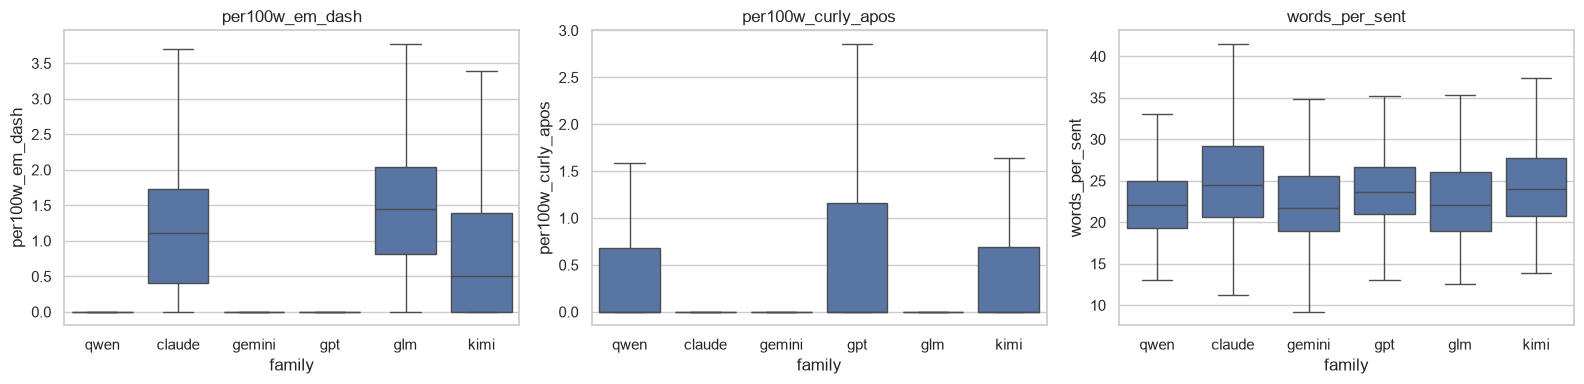

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["per100w_em_dash", "per100w_curly_apos", "words_per_sent"]):
    sns.boxplot(data=stylo, x="family", y=c, ax=ax, showfliers=False)
    ax.set_title(c)
plt.tight_layout()

## 4. Textlängen

Std der Länge innerhalb eines Prompts: 58.6 | insgesamt: 59.1


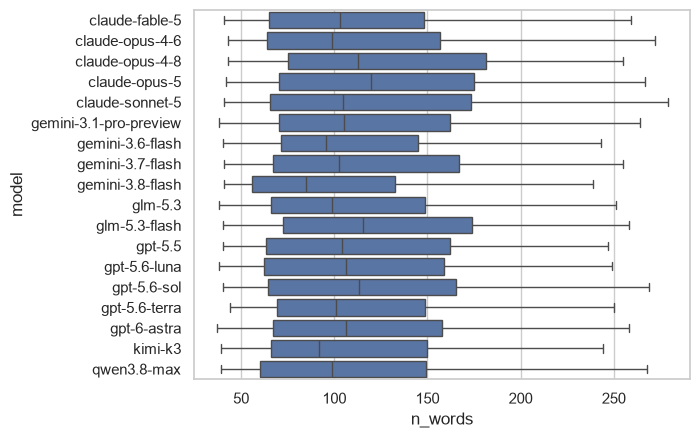

In [7]:
sns.boxplot(data=stylo, y="model", x="n_words", order=sorted(train.model.unique()), showfliers=False)
print("Std der Länge innerhalb eines Prompts:", train.assign(w=stylo.n_words).groupby("prompt_id").w.std().mean().round(1),
      "| insgesamt:", stylo.n_words.std().round(1))

## 5. Baseline und Fehleranalyse
GroupKFold nach `prompt_id`, damit derselbe Prompt nie in Train und Validierung zugleich vorkommt.

In [8]:
from src.cv import run_cv, get_folds
from src.models import get_model

folds = get_folds(train)
oof, classes, metrics = run_cv(get_model("tfidf_logreg"), train, folds)

Fold 0: acc=0.3741


Fold 1: acc=0.3352


Fold 2: acc=0.3630


Fold 3: acc=0.3741


Fold 4: acc=0.3135
{'accuracy': 0.352, 'macro_f1': 0.3367, 'log_loss': 1.9953, 'family_accuracy': 0.6717}


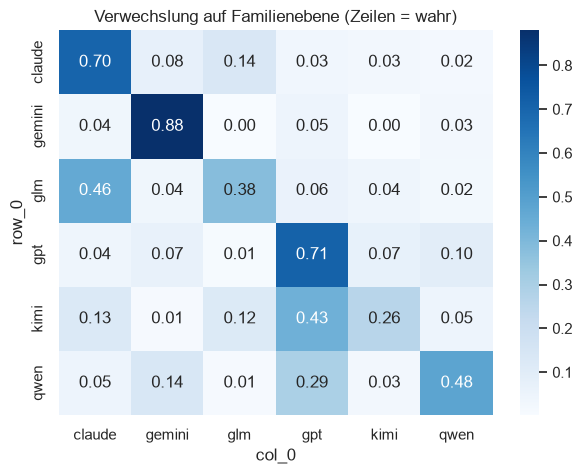

In [9]:
pred = classes[oof.argmax(1)]
fam_pred = pd.Series(pred).map(dict(zip(train.model, train.family)))
plt.figure(figsize=(7, 5))
sns.heatmap(pd.crosstab(train.family.values, fam_pred.values, normalize="index"), annot=True, fmt=".2f", cmap="Blues")
plt.title("Verwechslung auf Familienebene (Zeilen = wahr)");

model
claude-fable-5            0.107383
glm-5.3                   0.120000
gpt-5.6-sol               0.133333
gpt-5.6-terra             0.186667
glm-5.3-flash             0.246667
claude-opus-4-8           0.260000
gpt-5.6-luna              0.260000
kimi-k3                   0.260000
gemini-3.8-flash          0.346667
claude-sonnet-5           0.366667
gemini-3.7-flash          0.400000
gemini-3.6-flash          0.406667
gpt-5.5                   0.413333
qwen3.8-max               0.480000
claude-opus-4-6           0.513333
claude-opus-5             0.553333
gpt-6-astra               0.560000
gemini-3.1-pro-preview    0.720000
Name: ok, dtype: float64

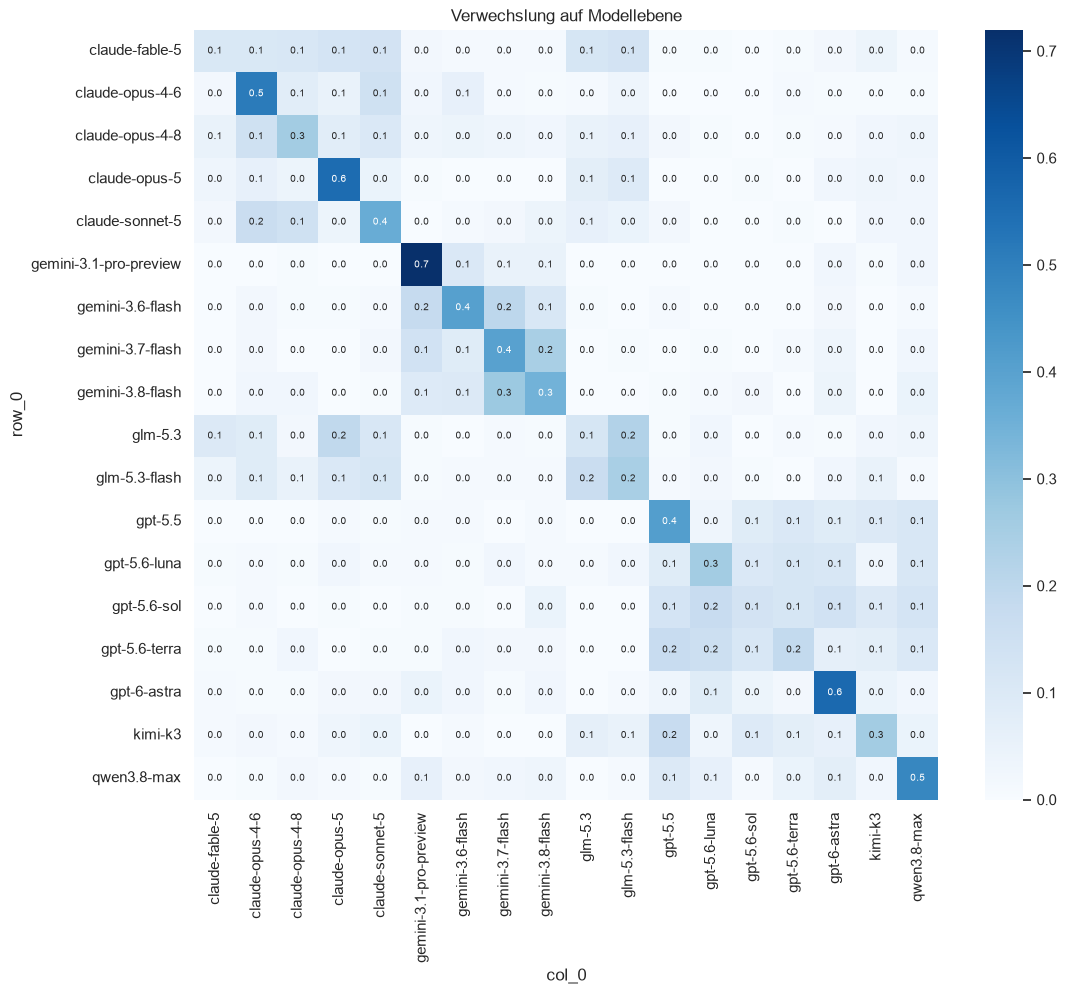

In [10]:
cm = pd.crosstab(train.model.values, pred, normalize="index")
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Verwechslung auf Modellebene");
train.assign(ok=pred == train.model).groupby("model").ok.mean().sort_values()  # = Recall je Modell; Mittelwert = Balanced Accuracy

## 6. Fazit
0. Bei Balanced Accuracy zählt jedes Modell gleich viel: Die Klassen mit dem **niedrigsten Recall** (claude-fable-5, gpt-5.6-sol, glm-5.3) bieten den größten Hebel.
1. **Familie ≈ leicht, Modell innerhalb der Familie ≈ schwer.** Am meisten lässt sich innerhalb von Claude (5 Modelle) und GPT (5 Modelle) gewinnen.
2. Claude und GLM werden stark verwechselt (gleiche Typografie). GPT, Kimi und Qwen ebenfalls.
3. Gemini lässt sich fast perfekt von den anderen Familien trennen.

Das weitere Vorgehen steht in `../PLAN.md`.